In [1]:
import pandas as pd
from pathlib import Path
from scipy.stats import chi2_contingency

DATA = Path("data")
df = pd.read_parquet(DATA / "model_table.parquet")

df["has_bureau"] = df["bureau_loan_count"].notna().astype(int)

table = pd.crosstab(df["has_bureau"], df["TARGET"])
print(table, "\n")

chi2, p, dof, expected = chi2_contingency(table)
print(f"chi-square = {chi2:.1f}")
print(f"p-value    = {p:.2e}")

TARGET           0      1
has_bureau               
0            39563   4457
1           243123  20368 

chi-square = 291.2
p-value    = 2.74e-65


           count  default_pct
age_group                    
20-29      45186        11.44
30-39      82349         9.59
40-49      76581         7.64
50-59      68109         6.12
60-69      35286         4.92

p-value = 0.00e+00


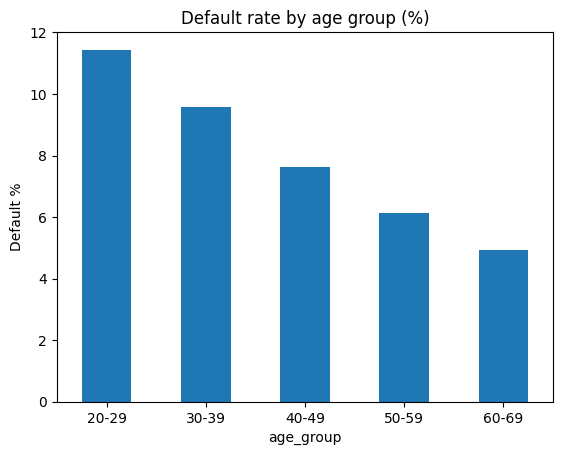

In [2]:
import matplotlib.pyplot as plt

df["age"] = -df["DAYS_BIRTH"] / 365.25
df["age_group"] = pd.cut(df["age"], bins=[20, 30, 40, 50, 60, 70],
                         labels=["20-29", "30-39", "40-49", "50-59", "60-69"])

age_table = df.groupby("age_group", observed=True)["TARGET"].agg(["count", "mean"])
age_table["default_pct"] = (age_table["mean"] * 100).round(2)
print(age_table[["count", "default_pct"]])

chi2, p, _, _ = chi2_contingency(pd.crosstab(df["age_group"], df["TARGET"]))
print(f"\np-value = {p:.2e}")

age_table["default_pct"].plot(kind="bar", title="Default rate by age group (%)")
plt.ylabel("Default %"); plt.xticks(rotation=0); plt.show()

In [3]:
from scipy.stats import mannwhitneyu

s = df[["EXT_SOURCE_2", "TARGET"]].dropna()
s["decile"] = pd.qcut(s["EXT_SOURCE_2"], 10, labels=range(1, 11))

dec = s.groupby("decile", observed=True)["TARGET"].mean().mul(100).round(2)
print("Default % by EXT_SOURCE_2 decile (1 = lowest score):")
print(dec)

stat, p = mannwhitneyu(s.loc[s.TARGET == 1, "EXT_SOURCE_2"],
                       s.loc[s.TARGET == 0, "EXT_SOURCE_2"])
print(f"\nMedian score, defaulters:     {s.loc[s.TARGET == 1, 'EXT_SOURCE_2'].median():.3f}")
print(f"Median score, non-defaulters: {s.loc[s.TARGET == 0, 'EXT_SOURCE_2'].median():.3f}")
print(f"p-value = {p:.2e}")

Default % by EXT_SOURCE_2 decile (1 = lowest score):
decile
1     18.35
2     12.08
3      9.96
4      8.36
5      7.42
6      6.65
7      5.85
8      4.88
9      4.20
10     2.97
Name: TARGET, dtype: float64

Median score, defaulters:     0.440
Median score, non-defaulters: 0.574
p-value = 0.00e+00


In [4]:
df["late_band"] = pd.cut(df["inst_late_rate"],
                         bins=[-0.01, 0, 0.05, 0.20, 1.0],
                         labels=["never late", "up to 5%", "5-20%", "over 20%"])
df["late_band"] = df["late_band"].cat.add_categories("no history").fillna("no history")

late = df.groupby("late_band", observed=True)["TARGET"].agg(["count", "mean"])
late["default_pct"] = (late["mean"] * 100).round(2)
print(late[["count", "default_pct"]])

chi2, p, _, _ = chi2_contingency(pd.crosstab(df["late_band"], df["TARGET"]))
print(f"\np-value = {p:.2e}")

             count  default_pct
late_band                      
never late  136636         6.80
up to 5%     40205         7.01
5-20%        77319         9.40
over 20%     37475        12.01
no history   15876         5.98

p-value = 1.91e-305


## Stage 5 findings: analysis and statistical tests

| Signal | Lowest-risk group | Highest-risk group | Ratio | Test | p-value |
|---|---|---|---|---|---|
| Bureau history | Has history: 7.73% | No history: 10.12% | 1.31× | Chi-square | < 0.001 |
| Age | 60–69: 4.92% | 20–29: 11.44% | 2.3× | Chi-square | < 0.001 |
| EXT_SOURCE_2 decile | Top 10%: 2.97% | Bottom 10%: 18.35% | 6.2× | Mann-Whitney U | < 0.001 |
| Late-payment rate (engineered) | Never late: 6.80% | Over 20% late: 12.01% | 1.8× | Chi-square | < 0.001 |

- With 307,511 applicants, almost any difference is statistically significant, so **effect size (ratio) matters more than p-values**.
- These are **associations, not causes**.
- **EXT_SOURCE_2** is the strongest single signal, but its meaning is undisclosed.
- **Age** is predictive but sensitive → flagged for the fairness review (Stage 8).
- The engineered **late-payment feature** adds real signal, validating the Stage 4 SQL work.